# EDA Summary: Enterprise Predictive Maintenance & IoT Sensor Optimization
**Dataset:** NASA CMAPSS Turbofan Engine Degradation (FD001, FD003)
**Author:** Gretchen Kolthoff
**Pipeline:** Databricks (PySpark, Delta Lake) medallion architecture

> *This EDA was written before modeling. Results are in `04_modeling`. Updated Oct 2026 to remove claims that did not hold up (cost figures, "LSTM handles multicollinearity"); the original pre-modeling decision rule is kept, with its outcome noted.*

---

## Hypothesis

**H₀:** Multivariate sensor readings from turbofan engines have no statistically significant predictive relationship with remaining useful life (RUL) beyond a naive mean baseline.

**H₁:** Sensor degradation patterns contain sufficient signal to predict RUL with meaningful accuracy, early enough to schedule removal before failure.

**Motivation:** In aviation, a missed engine failure is first a safety risk; time-based maintenance avoids that risk but removes engines with useful life left. This project tests whether sensor data can support predictive maintenance: removing an engine in the window before failure.

---

## What We Are Testing

1. **Can sensor readings predict RUL with low enough error to be operationally actionable?** — tested via RMSE and MAE against a Ridge regression baseline and an LSTM neural network.
2. **Does temporal sequence modeling (LSTM) outperform linear regression (Ridge) on this data?** — tested given the presence of multicollinearity and time-dependent degradation patterns.
3. **(Future work) Does a second fault mode (FD003) change generalization?** — FD003 is ingested through Silver but not modeled in this version.

---

## Dataset Characteristics

| | FD001 | FD003 |
|---|---|---|
| Training engines | 100 | 100 |
| Training rows | 20,631 | 24,720 |
| Test engines | 100 | 100 |
| Fault modes | 1 (HPC degradation) | 2 (HPC + fan degradation) |
| Operating conditions | 1 | 1 |
| RUL mean (train) | 107.8 cycles | 138.1 cycles |
| RUL std (train) | 68.9 cycles | 98.8 cycles |
| RUL max (train) | 361 cycles | 524 cycles |

FD003's higher variance (std = 98.8 vs. 68.9) and longer tail reflect its second fault mode — engines fail in more varied ways and at more varied times, making prediction harder and generalization more meaningful.

---

## Key EDA Findings

### Finding 1: RUL Distribution is Right-Skewed — Capping Required

Both FD001 and FD003 exhibit a right-skewed RUL distribution with a flat plateau in the low-RUL range (0–150 cycles) followed by a long tail. Engines with high RUL values (> 125 cycles) show no distinguishable sensor degradation signal — their readings are operationally indistinguishable from healthy engines at RUL = 300 vs. RUL = 200.

**Decision:** Cap RUL at **125 cycles**. Any observation with RUL > 125 is treated as RUL = 125. This focuses the model on the degradation window that matters to a maintenance scheduler and eliminates label noise from the healthy operating plateau.

*Without capping, a model could achieve deceptively low RMSE simply by predicting the mean — a known failure mode for RUL regression on this dataset.*

---

### Finding 2: 8 Features Confirmed Zero-Variance — Dropped

Six sensors and one operational setting were confirmed constant across all FD001 observations via standard deviation analysis:

**Dropped (zero or near-machine-epsilon variance):**
`sensor_1`, `sensor_5`, `sensor_6`, `sensor_10`, `sensor_16`, `sensor_18`, `sensor_19`, `op_setting_3`

Standard deviations ranged from exactly 0.0 (`sensor_18`, `sensor_19`) to 2.9e-11 (`sensor_1`) — all effectively constant. Including these features adds dimensionality with zero information gain and can destabilize coefficient estimation in Ridge regression.

**Remaining feature set: 14 sensors + 2 operational settings = 16 informative features**

---

### Finding 3: Strong Linear Signal Exists — Ridge is a Viable Baseline

Pearson correlation analysis between each sensor and capped RUL revealed strong linear relationships across multiple features:

**Top negatively correlated (increase as engine degrades):**
| Sensor | r | Interpretation |
|---|---|---|
| sensor_11 | -0.775 | Strongest degradation signal — rises toward failure |
| sensor_4 | -0.757 | Temperature/pressure proxy |
| sensor_15 | -0.721 | Consistent degradation indicator |
| sensor_17 | -0.681 | Secondary degradation signal |
| sensor_2 | -0.678 | Moderate degradation correlation |

**Top positively correlated (decrease as engine degrades):**
| Sensor | r | Interpretation |
|---|---|---|
| sensor_12 | +0.749 | Decreases as engine approaches failure |
| sensor_7 | +0.733 | Strong inverse degradation proxy |
| sensor_21 | +0.707 | Consistent with sensor_12 pattern |
| sensor_20 | +0.705 | Secondary positive signal |

`op_setting_1` and `op_setting_2` showed correlations of -0.006 and -0.010 respectively — effectively zero, consistent with FD001's single operating condition design.

**Implication:** The strength of linear correlations (up to |r| = 0.775) means Ridge regression is not a straw-man baseline — it is a legitimate competitor that the LSTM must meaningfully outperform to justify its complexity.

---

### Finding 4: Significant Multicollinearity

Pairwise feature correlation analysis identified one pair exceeding |r| > 0.9 and multiple pairs in the 0.80–0.85 range:

| Pair | |r| | Risk |
|---|---|---|
| sensor_9 ↔ sensor_14 | **0.963** | Severe — coefficient instability in Ridge |
| sensor_11 ↔ sensor_12 | 0.850 | High |
| sensor_4 ↔ sensor_11 | 0.830 | High |
| sensor_8 ↔ sensor_13 | 0.830 | High |

Ridge regression applies L2 regularization which shrinks coefficients but does not resolve instability when two features carry near-identical information (r = 0.963). The regularizer cannot determine which of the two to weight — it splits the coefficient arbitrarily.

Neither model "resolves" collinearity: an LSTM's gates address temporal dependencies and vanishing gradients, not correlated inputs, and its weights are not interpretable per feature anyway.

**Implication:** `sensor_14` is dropped, and feature importance for Ridge is reported **grouped by sensor**, since splitting credit between near-duplicate features is arbitrary.

---

### Finding 5: Temporal Bias — Requires Sequence-Aware Modeling

The CMAPSS dataset notes that each engine begins with "different degrees of initial wear and manufacturing variation which is unknown to the user." This creates a temporal bias: early cycles of a heavily worn engine may look identical in sensor space to late cycles of a lightly worn engine.

A model treating each row as an independent observation (Ridge regression with no lag features) cannot distinguish these states. An LSTM consuming sequences of sensor readings can learn that *the trajectory of change* — not just the current reading — is the degradation signal.

**Implication:** Rolling window features (lag windows of 30 cycles) will be engineered in the Silver layer to give Ridge regression partial access to temporal context. If Ridge with lag features approaches LSTM performance, it strengthens the case for the simpler model.

---

## Bias Assessment

| Bias Type | Present | Mitigation |
|---|---|---|
| Label distribution skew (high-RUL overrepresentation) | Yes | RUL capping at 125 cycles |
| Temporal / initial wear bias | Yes | LSTM sequence modeling; rolling window features for Ridge |
| Single fault mode (FD001 only) | Yes | Acknowledged as limitation; FD003 ingested for future work |
| Operational condition homogeneity | Yes | Acknowledged as limitation; FD002/FD004 excluded by scope |
| Survivorship bias (engines observed to failure only) | Inherent to dataset | No mitigation — documented in README |

---

## Metric Selection & Justification

### Primary Regression Metrics

**RMSE (Root Mean Squared Error)**
The primary evaluation metric. Penalizes large prediction errors quadratically — appropriate because predicting "30 cycles remaining" when the true value is 5 cycles has a categorically different business consequence than predicting "27 cycles" when the true value is 25. Large errors are catastrophic in a maintenance context; RMSE's sensitivity to them is a feature, not a bug.

**MAE (Mean Absolute Error)**
Secondary metric. More interpretable for business stakeholders: "on average, our RUL predictions are off by X cycles." Less sensitive to outliers, useful for understanding typical prediction quality independent of worst-case errors. Reported alongside RMSE to give a complete error picture.

**Why not R²:**
R² is a relative measure normalized to the variance of the target. On a capped distribution with artificially reduced variance (post-125-cap), R² can inflate artificially. RMSE and MAE are absolute and directly interpretable in units of engine cycles.

### Maintenance Alert Layer Metrics (Threshold Classification)

When the RUL regression output is thresholded into a binary maintenance alert ("failure within 30 cycles: yes/no"), classification metrics apply:

**Recall (primary):** The fraction of true imminent failures that the model correctly flags. A false negative — missing an impending failure — is a safety risk, so recall is the constraint.

**Precision (secondary):** The fraction of alerts that correspond to true failures. A false positive — an unnecessary inspection or early removal — costs time and useful engine life. The asymmetry means lower precision is tolerated to protect recall.

**F1 Score:** Harmonic mean of precision and recall. Reported for completeness but not the primary optimization target given the asymmetric cost structure.

**Added after review — standard CMAPSS protocol:** RMSE at each test engine's **last cycle** against `RUL_FD001.txt`, plus the PHM08 asymmetric score (late predictions penalized more). These make results comparable to the literature.

---

## Model Selection Summary

| Factor | Ridge Regression | LSTM |
|---|---|---|
| Strong linear correlations (|r| up to 0.775) | ✅ Favors | |
| Multicollinearity (sensor_9/14 = 0.963) | ⚠️ Coefficient instability (mitigated by dropping sensor_14) | ⚠️ Not addressed by gating either |
| Temporal degradation sequences | ⚠️ Partial (lag features) | ✅ Native |
| Unknown initial wear state | ❌ Cannot model | ✅ Learns trajectory |
| Interpretability for business output | ✅ Coefficients readable | ❌ Black box |
| Training speed | ✅ Fast | ⚠️ Slower |
| Serving simplicity | ✅ Simple | ⚠️ Heavier (needs 30-cycle history) |

**Decision:** Both models are trained. Ridge regression with 30-cycle rolling window features serves as the interpretable baseline. LSTM is the primary hypothesis. If RMSE difference is < 5 cycles, Ridge is preferred for production deployment on interpretability and operational simplicity grounds.

> **Outcome (Oct 2026):** the last-cycle RMSE gap is 4.5 cycles (17.51 vs. 13.05), just under this pre-set threshold, so Gold serves Ridge, consistent with the rule. The LSTM is kept as the champion candidate because it roughly halves the PHM08 score (664 → 308): it is much less likely to predict late, which matters more for safety than RMSE alone.

---

## Silver Layer: Feature Engineering Plan

Based on EDA findings, the following transformations are applied in the Silver layer:

1. **Drop** 8 zero-variance features
2. **Cap** RUL at 125 cycles
3. **Compute** rolling mean and rolling std (window = 30 cycles) per engine per sensor — gives Ridge temporal context
4. **Min-max normalize** all sensor features per subset (sensor scales vary by orders of magnitude)
5. **Drop** `sensor_14` (kept `sensor_9`) to reduce the 0.963 collinearity pair
6. **Key every per-engine operation on (`split`, `unit_id`)** — train and test reuse IDs 1–100 for different engines
7. **Write** Silver Delta tables `silver_fd001` and `silver_fd003`

In [0]:
# ============================================================
# CELL 1 — EDA Setup: Load Bronze Tables
# Notebook: 02_eda
# Purpose: Hypothesis-driven EDA before model selection
# ============================================================

# Load bronze tables
train_fd001 = spark.table("workspace.predictive_maintenance.bronze_fd001").filter("split = 'train'")
train_fd003 = spark.table("workspace.predictive_maintenance.bronze_fd003").filter("split = 'train'")

print(f"FD001 training engines: {train_fd001.select('unit_id').distinct().count()}")
print(f"FD003 training engines: {train_fd003.select('unit_id').distinct().count()}")

# Quick look
train_fd001.show(3, truncate=False)

FD001 training engines: 100
FD003 training engines: 100
+-------+-----------+------------+------------+------------+--------+--------+--------+--------+--------+--------+--------+--------+--------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+------+-----+--------------------------+
|unit_id|time_cycles|op_setting_1|op_setting_2|op_setting_3|sensor_1|sensor_2|sensor_3|sensor_4|sensor_5|sensor_6|sensor_7|sensor_8|sensor_9|sensor_10|sensor_11|sensor_12|sensor_13|sensor_14|sensor_15|sensor_16|sensor_17|sensor_18|sensor_19|sensor_20|sensor_21|subset|split|ingested_at               |
+-------+-----------+------------+------------+------------+--------+--------+--------+--------+--------+--------+--------+--------+--------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+------+-----+--------------------------+
|1      |1          |-7.0E-4     |-4.0

RUL computed. Sample:
+-------+-----------+---+
|unit_id|time_cycles|RUL|
+-------+-----------+---+
|      1|          1|191|
|      1|          2|190|
|      1|          3|189|
|      1|          4|188|
|      1|          5|187|
+-------+-----------+---+
only showing top 5 rows


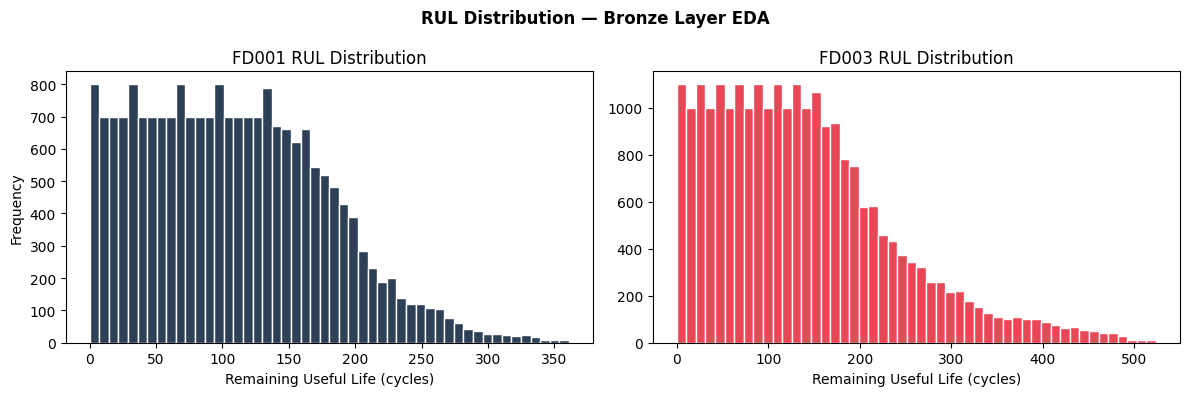


FD001 RUL stats:
count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64

FD003 RUL stats:
count    24720.000000
mean       138.077063
std         98.846675
min          0.000000
25%         61.000000
50%        123.000000
75%        190.000000
max        524.000000
Name: RUL, dtype: float64


In [0]:
# ============================================================
# CELL 2 — Compute RUL + Core EDA
# Hypothesis: Sensor readings contain statistically significant
# signal for predicting remaining useful life (RUL)
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# --- Step 1: Compute RUL for training data ---
# RUL = max cycle for that engine minus current cycle
window = Window.partitionBy("unit_id", "subset")

train_fd001_rul = train_fd001.withColumn(
    "max_cycle", F.max("time_cycles").over(window)
).withColumn(
    "RUL", F.col("max_cycle") - F.col("time_cycles")
).drop("max_cycle")

train_fd003_rul = train_fd003.withColumn(
    "max_cycle", F.max("time_cycles").over(window)
).withColumn(
    "RUL", F.col("max_cycle") - F.col("time_cycles")
).drop("max_cycle")

print("RUL computed. Sample:")
train_fd001_rul.select("unit_id","time_cycles","RUL").show(5)

# --- Step 2: RUL distribution ---
rul_pd = train_fd001_rul.select("RUL").toPandas()
rul_pd003 = train_fd003_rul.select("RUL").toPandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(rul_pd["RUL"], bins=50, color="#2E4057", edgecolor="white")
axes[0].set_title("FD001 RUL Distribution")
axes[0].set_xlabel("Remaining Useful Life (cycles)")
axes[0].set_ylabel("Frequency")

axes[1].hist(rul_pd003["RUL"], bins=50, color="#E84855", edgecolor="white")
axes[1].set_title("FD003 RUL Distribution")
axes[1].set_xlabel("Remaining Useful Life (cycles)")

plt.suptitle("RUL Distribution — Bronze Layer EDA", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"\nFD001 RUL stats:\n{rul_pd['RUL'].describe()}")
print(f"\nFD003 RUL stats:\n{rul_pd003['RUL'].describe()}")

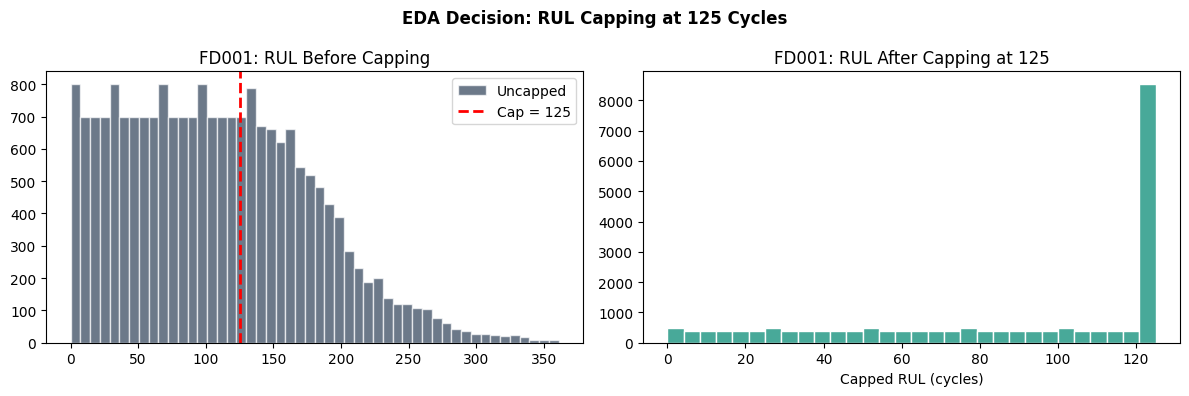

=== SENSOR STANDARD DEVIATIONS (FD001) ===
           sensor       std_dev
18  std_sensor_19  0.000000e+00
17  std_sensor_18  0.000000e+00
15  std_sensor_16  9.509693e-16
9   std_sensor_10  9.945689e-14
4    std_sensor_5  1.004047e-12
0    std_sensor_1  2.863957e-11
5    std_sensor_6  1.388985e-03
14  std_sensor_15  3.750504e-02
7    std_sensor_8  7.098548e-02
12  std_sensor_13  7.191892e-02
20  std_sensor_21  1.082509e-01
19  std_sensor_20  1.807464e-01
10  std_sensor_11  2.670874e-01
1    std_sensor_2  5.000533e-01
11  std_sensor_12  7.375534e-01
6    std_sensor_7  8.850923e-01
16  std_sensor_17  1.548763e+00
2    std_sensor_3  6.131150e+00
3    std_sensor_4  9.000605e+00
13  std_sensor_14  1.907618e+01
8    std_sensor_9  2.208288e+01

Low-variance sensors (std < 0.01) — candidates for removal:
['std_sensor_19', 'std_sensor_18', 'std_sensor_16', 'std_sensor_10', 'std_sensor_5', 'std_sensor_1', 'std_sensor_6']


In [0]:
# ============================================================
# CELL 3 — RUL Capping Decision + Sensor Variance Analysis
# EDA Finding: High RUL values (>125) show no degradation signal
# Decision: Cap RUL at 125 cycles for model training
# ============================================================

RUL_CAP = 125  # cycles — standard for CMAPSS, justified by EDA

from pyspark.sql.functions import least, col, lit, stddev, mean, variance
import matplotlib.pyplot as plt
import pandas as pd

# Apply cap
train_fd001_capped = train_fd001_rul.withColumn(
    "RUL_capped", least(col("RUL"), lit(RUL_CAP))
)
train_fd003_capped = train_fd003_rul.withColumn(
    "RUL_capped", least(col("RUL"), lit(RUL_CAP))
)

# Visualize capped vs uncapped
rul_capped_pd = train_fd001_capped.select("RUL_capped").toPandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(rul_pd["RUL"], bins=50, color="#2E4057", edgecolor="white", alpha=0.7, label="Uncapped")
axes[0].axvline(RUL_CAP, color="red", linestyle="--", linewidth=2, label=f"Cap = {RUL_CAP}")
axes[0].set_title("FD001: RUL Before Capping")
axes[0].legend()

axes[1].hist(rul_capped_pd["RUL_capped"], bins=30, color="#48A999", edgecolor="white")
axes[1].set_title(f"FD001: RUL After Capping at {RUL_CAP}")
axes[1].set_xlabel("Capped RUL (cycles)")

plt.suptitle("EDA Decision: RUL Capping at 125 Cycles", fontweight="bold")
plt.tight_layout()
plt.show()

# --- Sensor variance analysis ---
# Identify which sensors have near-zero variance (no signal)
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

stats = train_fd001_capped.select(
    [stddev(c).alias(f"std_{c}") for c in sensor_cols]
).toPandas().T.reset_index()
stats.columns = ["sensor", "std_dev"]
stats = stats.sort_values("std_dev")

print("=== SENSOR STANDARD DEVIATIONS (FD001) ===")
print(stats.to_string())
print("\nLow-variance sensors (std < 0.01) — candidates for removal:")
print(stats[stats["std_dev"] < 0.01]["sensor"].tolist())

Dropping 8 zero-variance features: ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19', 'op_setting_3']
Remaining sensors for modeling: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Feature count: 14


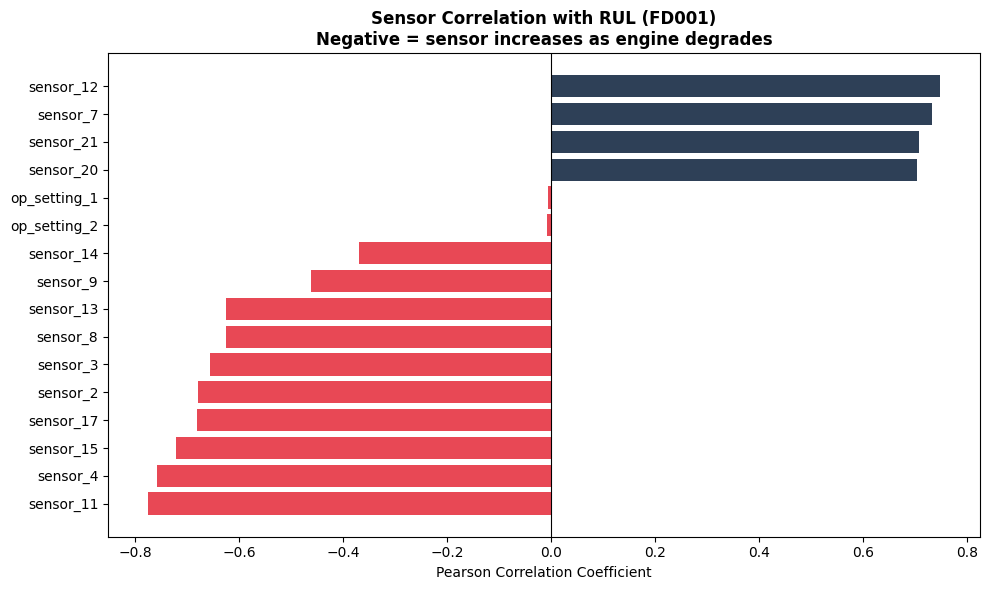


Top positively correlated sensors (decrease as engine ages):
op_setting_1   -0.005556
sensor_20       0.704626
sensor_21       0.707334
sensor_7        0.733021
sensor_12       0.748870
Name: RUL_capped, dtype: float64

Top negatively correlated sensors (increase as engine ages):
sensor_11   -0.775230
sensor_4    -0.757157
sensor_15   -0.720858
sensor_17   -0.680829
sensor_2    -0.678458
Name: RUL_capped, dtype: float64


In [0]:
# ============================================================
# CELL 4 — Feature Selection: Drop Zero-Variance Sensors
# + Sensor-RUL Correlation Analysis
# EDA Finding: 6 sensors have zero variance in FD001 (constant)
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Sensors confirmed zero-variance in FD001 — drop from features
SENSORS_TO_DROP = ["sensor_1", "sensor_5", "sensor_6", 
                   "sensor_10", "sensor_16", "sensor_18", "sensor_19"]

# Also drop op_setting_3 — confirmed constant at 100.0 in Cell 1 EDA
SETTINGS_TO_DROP = ["op_setting_3"]

COLS_TO_DROP = SENSORS_TO_DROP + SETTINGS_TO_DROP

print(f"Dropping {len(COLS_TO_DROP)} zero-variance features: {COLS_TO_DROP}")

# Remaining sensor features
remaining_sensors = [f"sensor_{i}" for i in range(1, 22) 
                     if f"sensor_{i}" not in SENSORS_TO_DROP]
print(f"Remaining sensors for modeling: {remaining_sensors}")
print(f"Feature count: {len(remaining_sensors)}")

# --- Sensor-RUL Pearson Correlation ---
# Hypothesis test: which sensors correlate with RUL degradation?
feature_cols = remaining_sensors + ["op_setting_1", "op_setting_2"]
target = "RUL_capped"

# Convert to pandas for correlation
corr_pd = train_fd001_capped.select(feature_cols + [target]).toPandas()
correlations = corr_pd.corr()[target].drop(target).sort_values()

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#E84855" if v < 0 else "#2E4057" for v in correlations.values]
ax.barh(correlations.index, correlations.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Sensor Correlation with RUL (FD001)\nNegative = sensor increases as engine degrades", 
             fontweight="bold")
ax.set_xlabel("Pearson Correlation Coefficient")
plt.tight_layout()
plt.show()

print("\nTop positively correlated sensors (decrease as engine ages):")
print(correlations.tail(5))
print("\nTop negatively correlated sensors (increase as engine ages):")
print(correlations.head(5))

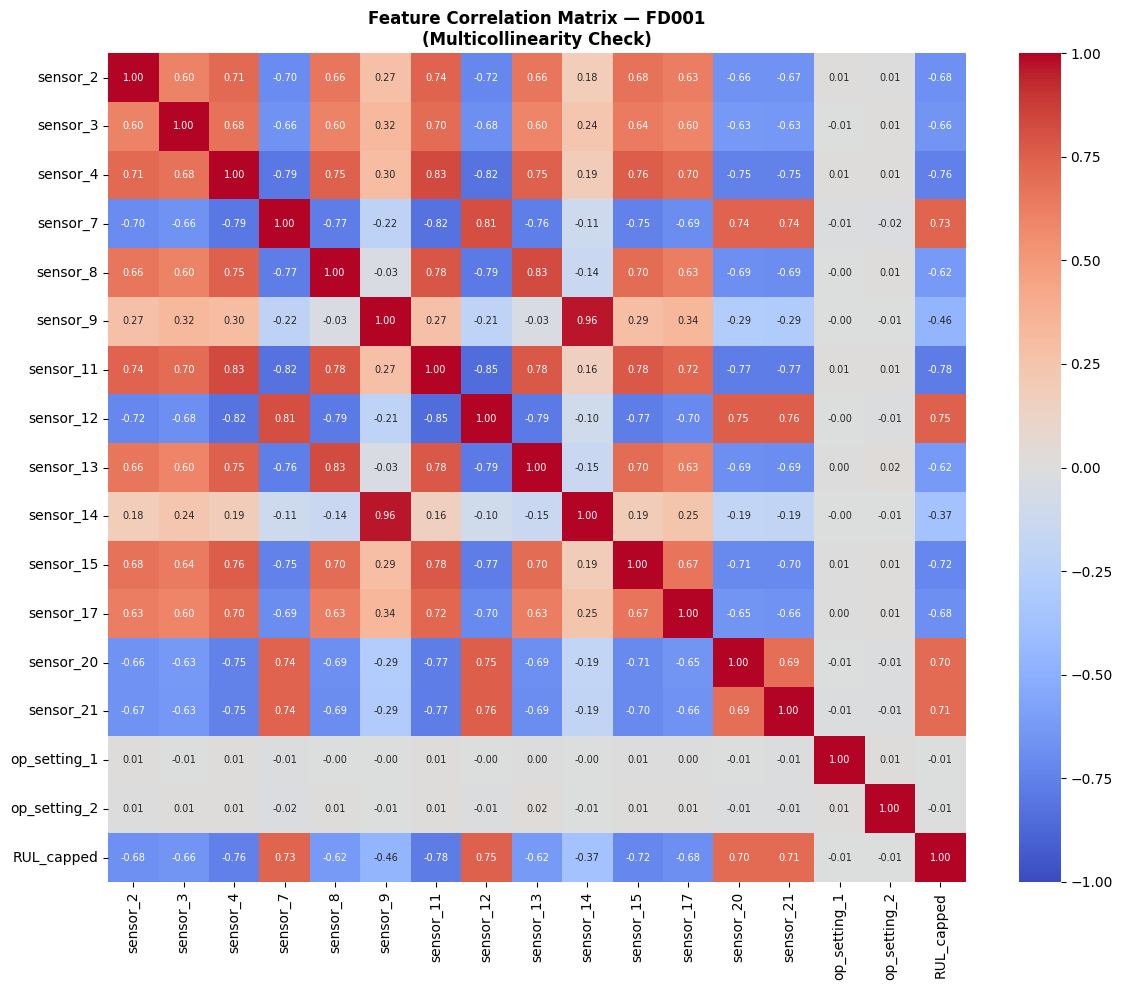

=== HIGH MULTICOLLINEARITY PAIRS (|r| > 0.9) ===
  sensor_9 <-> sensor_14: 0.963

Note: Highly correlated features may cause instability in Ridge regression.
Resolution: drop sensor_14 (keep sensor_9); report Ridge importance grouped by sensor.

=== EDA COMPLETE — DECISIONS FOR SILVER LAYER ===
  Drop features:     ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19', 'op_setting_3']
  RUL cap:           125 cycles
  Informative features: 16
  Model candidates:  Ridge Regression, LSTM


In [0]:
# ============================================================
# CELL 5 — Multicollinearity Check + EDA Summary
# High inter-sensor correlation → may need PCA or selective drop
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt

# Select informative sensors only
informative_sensors = [
    "sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_8",
    "sensor_9", "sensor_11", "sensor_12", "sensor_13", "sensor_14",
    "sensor_15", "sensor_17", "sensor_20", "sensor_21",
    "op_setting_1", "op_setting_2", "RUL_capped"
]

corr_matrix = train_fd001_capped.select(informative_sensors).toPandas().corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True, fmt=".2f", cmap="coolwarm",
    center=0, vmin=-1, vmax=1,
    annot_kws={"size": 7},
    ax=ax
)
ax.set_title("Feature Correlation Matrix — FD001\n(Multicollinearity Check)", 
             fontweight="bold")
plt.tight_layout()
plt.show()

# Flag high inter-feature correlations (>0.9, excluding RUL)
feature_corr = corr_matrix.drop("RUL_capped").drop("RUL_capped", axis=1)
high_corr_pairs = []
for i in range(len(feature_corr.columns)):
    for j in range(i+1, len(feature_corr.columns)):
        val = abs(feature_corr.iloc[i, j])
        if val > 0.9:
            high_corr_pairs.append((
                feature_corr.columns[i],
                feature_corr.columns[j],
                round(val, 3)
            ))

print("=== HIGH MULTICOLLINEARITY PAIRS (|r| > 0.9) ===")
if high_corr_pairs:
    for a, b, v in sorted(high_corr_pairs, key=lambda x: -x[2]):
        print(f"  {a} <-> {b}: {v}")
    print("\nNote: Highly correlated features may cause instability in Ridge regression.")
    print("Resolution: drop sensor_14 (keep sensor_9); report Ridge importance grouped by sensor.")
else:
    print("No pairs with |r| > 0.9 found.")

print("\n=== EDA COMPLETE — DECISIONS FOR SILVER LAYER ===")
print(f"  Drop features:     {COLS_TO_DROP}")
print(f"  RUL cap:           {RUL_CAP} cycles")
print(f"  Informative features: {len(informative_sensors)-1}")
print(f"  Model candidates:  Ridge Regression, LSTM")